# Customer churn with a Random Forest

**Ernestas Lazurkevičius — PRIf-24/2, VilniusTech**

An adaptation of the lecturer's `AdventureWorksDW_Decision_Forests.ipynb`
(Algirdas Laukaitis).

## What the original notebook does

The original predicts the same `BikeBuyer` flag as the neural-network notebook, from the
same AdventureWorks `vTargetMail.csv` data — but with a **random forest** instead of a
neural network. That is the point of the pair: same data, same question, two different
families of model, so they can be compared directly.

A random forest trains many decision trees, each on a random subset of the rows and
columns, and lets them vote. A single decision tree is a chain of yes/no questions
(`Is Contract = Month-to-month?`, `Is tenure < 7?`). One tree alone overfits badly;
hundreds of them, each seeing slightly different data, average their errors out.

The original follows the same five steps as the neural-network notebook:

1. Load the CSV, drop identifier columns, rename `BikeBuyer` to `target`, split **90:10**.
2. Convert the DataFrames with `tfdf.keras.pd_dataframe_to_tf_dataset`.
3. Build `tfdf.keras.RandomForestModel(num_trees=10, max_depth=15)`.
4. Train, evaluate (**80.9 %** accuracy), plot out-of-bag curves, draw one tree.
5. Save, reload, predict for one customer.

### The one structural difference from the neural network

Step 1 splits **90:10**, not 80:10:10 — there is no validation set, and the original
notes this explicitly. The reason is **out-of-bag evaluation**. Each tree trains on a
random sample of the rows, so roughly a third of the data is unused by any given tree.
Those unused rows are that tree's private held-out set. Averaged across the forest, this
gives a validation score for free, from the training data, with no split needed.

That is also why training is a single pass with no epochs, no learning rate and no loss
curve to watch. The neural-network notebook needs 30 epochs of gradient descent; the
forest is built once.

## What this notebook changes

| | Original | This notebook |
|---|---|---|
| Dataset | AdventureWorks `vTargetMail.csv` | **Telco Customer Churn** (Kaggle) |
| Question | Will the customer buy a bike? | Will the customer cancel the subscription? |
| Library | `tensorflow_decision_forests` | **`ydf`** — same algorithm, see below |
| Trees | 10 | 300 |

**Why the same dataset as my neural-network rebuild.** The lecturer's two notebooks run
on identical data so the two model families can be compared. Reproducing that comparison
is the point, so this notebook uses the same Telco Churn data as
`TelcoChurn_NN_1.ipynb` — and, as Step 1 shows, **the exact same test rows**. The
comparison at the end is therefore a fair one rather than two numbers from different
splits.

Every deviation from the original is marked with a **`# CHANGE:`** comment.

---
# Step 1. From a CSV data file available online to 2 DataFrame tables: training and test

## 1.1 Load the Telco Customer Churn data

Loaded over HTTPS from a public GitHub mirror of the IBM sample file, which keeps the
original's "read a CSV straight from a URL" approach — no Kaggle credentials, no upload.

In [1]:
%pip install -q ydf

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import ydf

print("ydf", ydf.__version__)

ydf 0.16.1


In [3]:
# CHANGE: different source URL; sep='\t' removed (this file is comma-separated,
# while vTargetMail.csv is tab-separated despite its .csv name).
DATA_URL = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
)

df = pd.read_csv(DATA_URL)

print("The dataframe has {} rows and {} columns.".format(df.shape[0], df.shape[1]))

The dataframe has 7043 rows and 21 columns.


## 1.2 Examine the data

In [4]:
df[0:5]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1.3 Remove the attributes we don't need, and fix the target column

Identical in purpose to the original's cleaning step, and identical in code to my
neural-network rebuild — deliberately, because the two notebooks must see the same data
for the comparison at the end to mean anything.

* **`customerID`** is a unique key. Every value appears exactly once, so it carries no
  generalisable pattern.
* **`TotalCharges`** arrives as text: 11 of the 7,043 rows hold a blank string. All 11
  have `tenure = 0` — customers who signed up but have not been billed yet — so `0.0`
  is the factually correct value rather than a guess.
* **`Churn`** holds `"Yes"`/`"No"` and is mapped to `1`/`0`.

A note specific to decision forests: this last step is **not strictly required** here.
Unlike a neural network, a forest can split on a string label and on raw categorical
columns without any encoding at all — no `StringLookup`, no multi-hot vectors, no
normalisation. It is done anyway so both notebooks work from an identical table.

In [5]:
# CHANGE: only the identifier column is dropped (the original drops 19 columns,
# because AdventureWorks carries names, addresses and duplicate-language columns).
df.drop(columns=["customerID"], inplace=True)

# CHANGE (new step): TotalCharges arrives as text because 11 rows are blank.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)

# CHANGE (new step): the target is "Yes"/"No" text and must become 1/0.
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0}).astype("int64")

df.rename(columns={"Churn": "target"}, inplace=True)

print(df.iloc[0])

gender                        Female
SeniorCitizen                      0
Partner                          Yes
Dependents                        No
tenure                             1
PhoneService                      No
MultipleLines       No phone service
InternetService                  DSL
OnlineSecurity                    No
OnlineBackup                     Yes
DeviceProtection                  No
TechSupport                       No
StreamingTV                       No
StreamingMovies                   No
Contract              Month-to-month
PaperlessBilling                 Yes
PaymentMethod       Electronic check
MonthlyCharges                 29.85
TotalCharges                   29.85
target                             0
Name: 0, dtype: object


### What a forest does *not* need

Worth stating explicitly, because it is the main practical advantage over the neural
network and it is invisible if you only read the code.

| | Neural network notebook | This notebook |
|---|---|---|
| Categorical columns | `StringLookup` + `CategoryEncoding` per column | **nothing** |
| Numeric columns | `Normalization` adapted on the training split | **nothing** |
| Pixel/value scaling | must match the model's expected range | **irrelevant** |
| Feature engineering cells | ~40 lines | **0 lines** |

A decision tree asks `is this value above or below a threshold?`, which is unaffected by
scale — multiplying a column by 1,000 changes nothing. And it asks
`is this category one of {A, C, F}?` directly, so text needs no encoding. All the
preprocessing machinery in the neural-network notebook exists to work around limitations
a forest does not have.

## 1.4 Split the DataFrame into training and test sets

**90:10, with no validation set** — out-of-bag evaluation replaces it, as explained above.

Two changes from the original, both carried over from my neural-network rebuild:

* `.iloc` slicing instead of `np.split`, which raises
  `FutureWarning: DataFrame.swapaxes is deprecated` when applied to a DataFrame.
* `random_state=42` so the split is reproducible — the original reshuffles on every run,
  so its accuracy cannot be reproduced or defended.

The seed matters more than usual here. It is the **same seed and the same shuffle** as
`TelcoChurn_NN_1.ipynb`, which cut the data 80:10:10. The first 90 % of that shuffle is
exactly the neural network's training plus validation rows, and the last 10 % is exactly
its test rows. So the forest trains on everything the network saw and is judged on
**the identical 705 test rows** — neither model has ever seen them.

In [6]:
# CHANGE: .iloc slicing instead of np.split, and random_state=42 so the split is
# reproducible AND identical to the one in TelcoChurn_NN_1.ipynb.
shuffled = df.sample(frac=1, random_state=42)

split_at = int(0.9 * len(shuffled))

train = shuffled.iloc[:split_at]
test = shuffled.iloc[split_at:]

print(len(train), "training examples")
print(len(test), "test examples")
print()
print("The neural-network notebook used the same shuffle with an 80:10:10 cut,")
print("so these", len(test), "test rows are the same rows it was scored on.")

6338 training examples
705 test examples

The neural-network notebook used the same shuffle with an 80:10:10 cut,
so these 705 test rows are the same rows it was scored on.


---
# Step 2. From DataFrame table to model input

The original converts both DataFrames with
`tfdf.keras.pd_dataframe_to_tf_dataset(train, label='target')`, which wraps them as
`tf.data.Dataset` objects because TF-DF presents itself as a Keras model.

`ydf` reads a pandas DataFrame directly, so this step disappears entirely — the
DataFrames from Step 1 are passed straight to the learner in Step 3.

## Why `ydf` rather than `tensorflow_decision_forests`

This is the one substantive library change, and it is not arbitrary.

TF-DF is a **Keras wrapper around Yggdrasil Decision Forests (YDF)**, a C++ library.
The `ydf` package is the direct Python API for that same engine — same algorithms, same
authors at Google, same model format, no TensorFlow dependency.

TensorFlow's own documentation now states the position plainly:

> **"Prefer YDF for new projects."** YDF *"extends the capabilities of TF-DF, offering
> new features, a simplified API, faster training times, updated documentation, and
> enhanced compatibility with popular ML libraries."*

The practical problems with TF-DF are concrete:

* **It does not support Keras 3.** TensorFlow has shipped Keras 3 by default since 2.16,
  so TF-DF needs the `tf_keras` compatibility package or an older TensorFlow. This is
  visible in the original's own output, which returns a `tf_keras.src.callbacks.History`
  object.
* **Its version is pinned to an exact TensorFlow release** — TF-DF 1.12.0 requires
  TensorFlow 2.19.0, 1.11.0 requires 2.18.0, and so on, because its C++ ABI is not stable
  across releases. A mismatch produces errors like `undefined symbol: _ZN10tensorflow...`.
* Installing it therefore silently downgrades TensorFlow, which can break other notebooks
  in the same runtime.

The original's `!pip install tensorflow_decision_forests` worked when it was written. The
TF-DF route is kept as a commented alternative below so either can be defended.

Source: [TensorFlow Decision Forests — Known Issues](https://www.tensorflow.org/decision_forests/known_issues)

In [7]:
# The original's TF-DF route, kept for reference:
#
# !pip install tensorflow_decision_forests
# import tensorflow_decision_forests as tfdf
#
# train_ds = tfdf.keras.pd_dataframe_to_tf_dataset(train, label='target')
# test_ds  = tfdf.keras.pd_dataframe_to_tf_dataset(test,  label='target')
# model_1 = tfdf.keras.RandomForestModel(num_trees=300, max_depth=15)
# model_1.fit(train_ds)
#
# Note: this pins TensorFlow to a specific version and requires tf_keras,
# because TF-DF does not support Keras 3.

---
# Step 3. Model

In `ydf` the **learner** is the configuration and `train()` returns the **model**. The
original's `tfdf.keras.RandomForestModel(...)` is the same idea in Keras clothing.

The hyperparameters:

* **`num_trees=300`.** The original passes `num_trees=10`, though its own commented-out
  line suggests 100 and the filename it saves to is
  `..._RandomForestModel_trees300`. Ten trees is far too few — the whole mechanism
  depends on averaging many of them. 300 is used here, which matches what the original's
  filename claims.
* **`max_depth=15`.** Unchanged. It caps how many questions deep any single tree can go,
  which limits how finely a tree can carve up the training data.
* **`compute_oob_variable_importances=True`.** Not in the original. It costs a little
  training time and unlocks the permutation-based importance measure used further down.

In [8]:
# CHANGE: 300 trees instead of 10 (the original's own filename says 300),
# and out-of-bag variable importances enabled.
learner = ydf.RandomForestLearner(
    label="target",
    num_trees=300,
    max_depth=15,
    compute_oob_variable_importances=True,
)

print(learner)

Learner: RANDOM_FOREST
Task: Task.CLASSIFICATION
Class: ydf.RandomForestLearner
Hyper-parameters: ydf.{'adapt_bootstrap_size_ratio_for_maximum_training_duration': False, 'allow_na_conditions': False, 'bootstrap_size_ratio': 1.0, 'bootstrap_training_dataset': True, 'categorical_algorithm': 'CART', 'categorical_set_split_greedy_maximum_mask_size': -1, 'categorical_set_split_greedy_sampling': 0.1, 'categorical_set_split_max_num_items': -1, 'categorical_set_split_min_item_frequency': 1, 'compute_oob_performances': True, 'compute_oob_variable_importances': True, 'growing_strategy': 'LOCAL', 'honest': False, 'honest_fixed_separation': False, 'honest_ratio_leaf_examples': 0.5, 'in_split_min_examples_check': True, 'keep_non_leaf_label_distribution': True, 'max_depth': 15, 'max_num_nodes': None, 'maximum_model_size_in_memory_in_bytes': -1.0, 'maximum_training_duration_seconds': -1.0, 'mhld_oblique_max_num_attributes': None, 'mhld_oblique_sample_attributes': None, 'min_examples': 5, 'missing_val

---
# Step 4. Train and evaluate the model

## Train 🏃‍♂️

One pass. No epochs, no learning rate, no loss curve — compare this with the 30 epochs
of gradient descent in the neural-network notebook. On this dataset it takes a couple of
seconds on CPU.

In [9]:
model = learner.train(train)

Train model on 6338 examples


Model trained in 0:00:03.231247


## Evaluate ⚖️

The original calls `model_1.compile(metrics=['accuracy'])` and then `evaluate`, and its
output reads `loss: 0.0000e+00 - accuracy: 0.8091`. That zero loss is not a bug and not a
perfect score: TF-DF does not optimise a Keras loss function, so the field is simply
unused. It is a confusing artefact of wearing a Keras interface over a non-Keras
algorithm. `ydf` reports a real loss.

In [10]:
evaluation = model.evaluate(test)

print(f"Test accuracy: {evaluation.accuracy:.4f}")
print(f"Test loss:     {evaluation.loss:.4f}")
print(f"Test rows:     {evaluation.num_examples}")

Test accuracy: 0.7986
Test loss:     0.4783
Test rows:     705


### Out-of-bag accuracy — the validation score that needs no validation set

The score below is computed from the training data alone, using each tree's unused rows.
It should land close to the test accuracy above. When it does, it is good evidence that
the model is not overfitting.

In [11]:
# CHANGE (new cell): make the out-of-bag mechanism explicit.
oob = model.self_evaluation()

print(f"Out-of-bag accuracy: {oob.accuracy:.4f}   (from training data, no split needed)")
print(f"Test accuracy:       {evaluation.accuracy:.4f}   (705 held-out rows)")
print(f"Difference:          {abs(oob.accuracy - evaluation.accuracy):.4f}")

Out-of-bag accuracy: 0.7968   (from training data, no split needed)
Test accuracy:       0.7986   (705 held-out rows)
Difference:          0.0018


## Plotting the training logs 🧾

How accuracy improves as trees are added. This is the forest's equivalent of a learning
curve, but it reads differently: adding trees to a random forest does not cause
overfitting, it just stops helping. The curve rises steeply, then flattens — and where it
flattens tells you how many trees you actually needed.

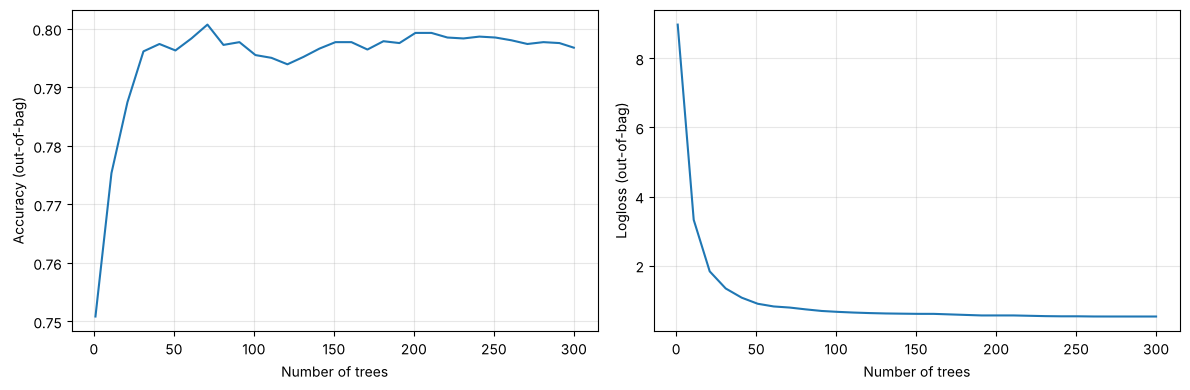

Out-of-bag accuracy with 1 tree(s):   0.7509
Out-of-bag accuracy with 300 trees:  0.7968


In [12]:
import matplotlib.pyplot as plt

logs = model.training_logs()

# CHANGE: ydf's log entries expose `.iteration`; TF-DF's expose `.num_trees`.
trees = [log.iteration for log in logs]
accuracies = [log.evaluation.accuracy for log in logs]
losses = [log.evaluation.loss for log in logs]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(trees, accuracies)
plt.xlabel("Number of trees")
plt.ylabel("Accuracy (out-of-bag)")
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(trees, losses)
plt.xlabel("Number of trees")
plt.ylabel("Logloss (out-of-bag)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Out-of-bag accuracy with {trees[0]} tree(s):   {accuracies[0]:.4f}")
print(f"Out-of-bag accuracy with {trees[-1]} trees:  {accuracies[-1]:.4f}")

## Which columns the forest actually relies on

Not in the original, and the single strongest argument for using a forest here.

A neural network's 6,154 weights do not tell you which customer attributes drive churn.
A forest can be asked directly, and gives several answers depending on the question:

* **`MEAN_DECREASE_IN_ACCURACY`** — shuffle one column's values at random and measure how
  much out-of-bag accuracy drops. The most honest measure of "how much does this column
  actually contribute", because it tests the column by breaking it.
* **`NUM_AS_ROOT`** — how often a column was chosen as a tree's very first question. The
  first split is the most consequential one, so this highlights the strongest single
  discriminator.
* **`INV_MEAN_MIN_DEPTH`** — how close to the root a column tends to appear.

For a retention team this output is the deliverable, not the accuracy score: it says
which levers are worth pulling.

In [13]:
# CHANGE (new cell): variable importances - a forest can be interrogated,
# a neural network cannot.
importances = model.variable_importances()

for measure in ["MEAN_DECREASE_IN_ACCURACY", "NUM_AS_ROOT", "INV_MEAN_MIN_DEPTH"]:
    print(f"--- {measure} ---")
    for score, feature in importances[measure][:8]:
        print(f"  {feature:<22s} {score:.5f}")
    print()

--- MEAN_DECREASE_IN_ACCURACY ---
  tenure                 0.00852
  InternetService        0.00694
  Contract               0.00284
  TotalCharges           0.00079
  PaperlessBilling       0.00047
  Partner                0.00000
  MonthlyCharges         0.00000
  SeniorCitizen          -0.00016

--- NUM_AS_ROOT ---
  Contract               95.00000
  OnlineSecurity         66.00000
  TechSupport            55.00000
  tenure                 28.00000
  InternetService        23.00000
  PaymentMethod          17.00000
  OnlineBackup           7.00000
  DeviceProtection       5.00000

--- INV_MEAN_MIN_DEPTH ---
  Contract               0.22519
  tenure                 0.19883
  TotalCharges           0.15781
  MonthlyCharges         0.15391
  OnlineSecurity         0.14748
  InternetService        0.14560
  PaymentMethod          0.13257
  TechSupport            0.13044



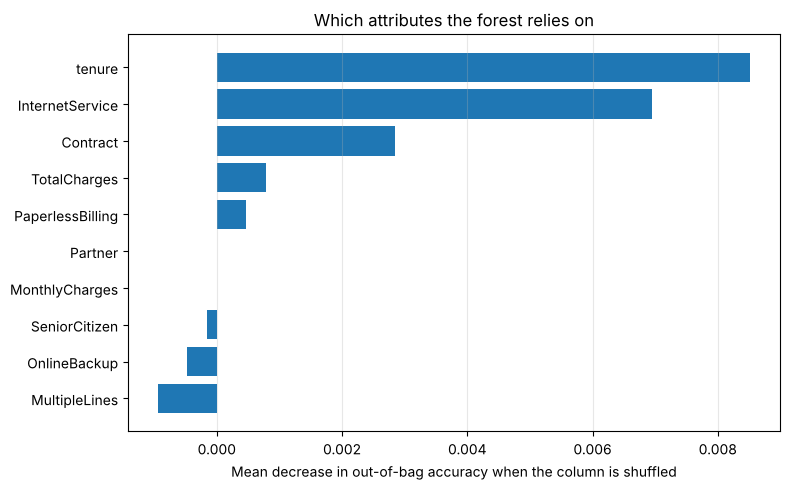

In [14]:
# CHANGE (new cell): chart the most defensible of the three measures.
top = importances["MEAN_DECREASE_IN_ACCURACY"][:10][::-1]
scores = [score for score, _ in top]
names = [name for _, name in top]

plt.figure(figsize=(8, 5))
plt.barh(names, scores)
plt.xlabel("Mean decrease in out-of-bag accuracy when the column is shuffled")
plt.title("Which attributes the forest relies on")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Where the mistakes are

The same per-class breakdown as the neural-network notebook, computed the same way, so
the two are comparable. Accuracy alone is misleading here: about 73 % of customers stay,
so predicting "nobody churns" would already score roughly 75 % on this test split.

In [15]:
# CHANGE (new cell): confusion matrix and per-class metrics.
from sklearn.metrics import confusion_matrix, classification_report

y_true = test["target"].to_numpy()
y_prob = model.predict(test.drop(columns=["target"]))
y_pred = (np.asarray(y_prob) >= 0.5).astype(int)

baseline = max((y_true == 0).mean(), (y_true == 1).mean())
print(f"Always-predict-majority baseline: {baseline:.4f}")
print(f"Random forest accuracy:           {(y_pred == y_true).mean():.4f}")
print()

print(pd.DataFrame(
    confusion_matrix(y_true, y_pred),
    index=["actual: stayed", "actual: churned"],
    columns=["pred: stayed", "pred: churned"],
))
print()
print(classification_report(
    y_true, y_pred, target_names=["stayed", "churned"], digits=3))

Always-predict-majority baseline: 0.7574
Random forest accuracy:           0.7986

                 pred: stayed  pred: churned
actual: stayed            483             51
actual: churned            91             80

              precision    recall  f1-score   support

      stayed      0.841     0.904     0.872       534
     churned      0.611     0.468     0.530       171

    accuracy                          0.799       705
   macro avg      0.726     0.686     0.701       705
weighted avg      0.785     0.799     0.789       705



## Let's choose one tree 🌲 from the forest and plot it

The original's most useful cell, and the clearest illustration of what a tree *is*.
Every node is one yes/no question about one column; follow the branches down and you
arrive at a prediction.

Only the first few levels are drawn — at `max_depth=15` a full tree is unreadable.

This is also where interpretability becomes concrete. A path through this tree is an
explanation a human can check and argue with: *month-to-month contract, short tenure,
no tech support → likely to churn*. A neural network has no equivalent.

In [16]:
# CHANGE: ydf's model.plot_tree() replaces
# tfdf.model_plotter.plot_model_in_colab(model_1, tree_idx=0, max_depth=15).
# Depth is limited to 3 because a depth-15 tree is unreadable on screen.
model.plot_tree(tree_idx=0, max_depth=3)

---
# Step 5. Perform inference 🛠

## Save 💾

The original saves with `model_1.save('..._trees300')` and then has to reload with
`tf.keras.layers.TFSMLayer(..., call_endpoint='serving_default')` — because Keras 3
cannot load a TensorFlow SavedModel directory back as a model. The result is a *layer*,
not a model, so it has no `.predict()`; the original's reload-and-predict cell is
commented out for exactly this reason, and the prediction at the end actually uses the
original in-memory model rather than the reloaded one.

`ydf` saves and loads a model as a model, so the round trip works.

In [17]:
# CHANGE: a round trip that actually round-trips.
export_path = "telco_churn_random_forest"
model.save(export_path)
print("Saved to", export_path)

Saved to telco_churn_random_forest


## Load ⚙️

In [18]:
reloaded_model = ydf.load_model(export_path)
print("Reloaded.")
print(reloaded_model)

Loading model from telco_churn_random_forest


Reloaded.
Model: RANDOM_FOREST
Task: CLASSIFICATION
Class: ydf.RandomForestModel
Use `model.describe()` for more details.



## New data 🗃️

One customer as a DataFrame row. No encoding, no scaling — raw values, as they appear in
the source CSV.

The high-risk profile from the neural-network notebook is reused, so the two models can
be asked about the same customer.

In [19]:
# CHANGE: a Telco customer record instead of an AdventureWorks one.
sample = {
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 95.70,
    "TotalCharges": 191.40,
}

loyal_sample = dict(
    sample,
    tenure=68,
    Contract="Two year",
    InternetService="DSL",
    OnlineSecurity="Yes",
    TechSupport="Yes",
    PaymentMethod="Credit card (automatic)",
    MonthlyCharges=64.00,
    TotalCharges=4352.00,
)

pd.DataFrame([sample, loyal_sample])

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.7,191.4
1,Female,0,No,No,68,Yes,No,DSL,Yes,No,No,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),64.0,4352.0


## Predict 🔮

`ydf` returns the probability of the positive class directly — there is no logit and no
manual `tf.nn.sigmoid`, because a forest predicts by counting votes across trees rather
than producing an unbounded score.

In [20]:
probabilities = reloaded_model.predict(pd.DataFrame([sample, loyal_sample]))

print("High-risk customer (2 months, month-to-month): %.1f %% chance of churning"
      % (100 * float(probabilities[0])))
print("Loyal customer  (68 months, two-year contract): %.1f %% chance of churning"
      % (100 * float(probabilities[1])))

High-risk customer (2 months, month-to-month): 90.3 % chance of churning
Loyal customer  (68 months, two-year contract): 0.3 % chance of churning


---
# Random forest vs neural network, on identical data

The reason the lecturer provides both notebooks. Both models were trained on the same
Telco Churn data, with the same shuffle seed, and scored on the **same 705 test rows**.

The neural-network figures below are the measured results from `TelcoChurn_NN_1.ipynb`,
not estimates.

In [21]:
# CHANGE (new cell): the head-to-head the paired notebooks invite.
# Neural network figures measured in TelcoChurn_NN_1.ipynb on the same test rows.
NN_RESULTS = {
    "Accuracy": 0.803,
    "Churn precision": 0.620,
    "Churn recall": 0.497,
}

report = classification_report(
    y_true, y_pred, target_names=["stayed", "churned"], digits=3, output_dict=True)

comparison = pd.DataFrame({
    "Neural network": [
        NN_RESULTS["Accuracy"],
        NN_RESULTS["Churn precision"],
        NN_RESULTS["Churn recall"],
    ],
    "Random forest": [
        round((y_pred == y_true).mean(), 3),
        round(report["churned"]["precision"], 3),
        round(report["churned"]["recall"], 3),
    ],
}, index=["Accuracy", "Churn precision", "Churn recall"])

print(comparison)
print()
print("Preprocessing code needed:   neural network ~40 lines, random forest 0")
print("Training:                    neural network 30 epochs, random forest 1 pass")
print("Can it tell you WHY:         neural network no, random forest yes")

                 Neural network  Random forest
Accuracy                  0.803          0.799
Churn precision           0.620          0.611
Churn recall              0.497          0.468

Preprocessing code needed:   neural network ~40 lines, random forest 0
Training:                    neural network 30 epochs, random forest 1 pass
Can it tell you WHY:         neural network no, random forest yes


---
# Summary

## The pipeline, unchanged from the original

1. Load a labelled table and split it **90:10** — no validation set, because out-of-bag
   evaluation provides one for free.
2. Hand the table to the learner. No encoding, no normalisation.
3. Configure a random forest: number of trees, maximum depth.
4. Train in one pass; evaluate on held-out rows; inspect out-of-bag curves and one tree.
5. Save, reload, predict for a single customer.

## What changed, and why

| # | Change | Reason |
|---|---|---|
| 1 | Telco Churn instead of `vTargetMail.csv` | the assignment requires own or business data; also lets this be compared with my neural-network rebuild |
| 2 | `ydf` instead of `tensorflow_decision_forests` | TF-DF does not support Keras 3, pins an exact TensorFlow version, and TensorFlow's own docs say to prefer YDF for new projects |
| 3 | `num_trees=300` instead of `10` | 10 trees undermines the averaging the method depends on — and the original's own save filename says 300 |
| 4 | `.iloc` slicing instead of `np.split`, plus `random_state=42` | removes a `FutureWarning`; makes the result reproducible and the test rows identical to the NN notebook's |
| 5 | `TotalCharges` repaired, `Churn` mapped to 1/0 | this dataset's quirks; AdventureWorks needed neither |
| 6 | Variable importances added, with a chart | the main reason to pick a forest; absent from the original |
| 7 | Out-of-bag vs test accuracy compared explicitly | makes the mechanism the 90:10 split depends on visible |
| 8 | Confusion matrix and per-class metrics | the classes are imbalanced, so accuracy alone misleads |
| 9 | Head-to-head comparison with the neural network | the point of the lecturer providing both notebooks |
| 10 | `max_depth=3` when plotting the tree | a depth-15 tree is unreadable |
| 11 | A save/load round trip that works | the original's reload produces a `TFSMLayer`, which has no `.predict()` |

## Defects found in the original

| # | Defect | Effect |
|---|---|---|
| 1 | `viz_cmodel` and `AdventDW_features` are used in the last two cells but **never defined** — the cell that would define them is entirely commented out | both cells raise `NameError`; confirmed by static analysis |
| 2 | Trains `num_trees=10` but saves to a file named `..._trees300` | the filename misstates what the model is |
| 3 | `np.split(df.sample(frac=1), ...)` | raises `FutureWarning`, and with no `random_state` the reported accuracy cannot be reproduced |
| 4 | Reloaded model is a `TFSMLayer`, which has no `.predict()` | the reload-and-predict cell is commented out; the final prediction silently uses the in-memory model instead |
| 5 | `loss: 0.0000e+00` in the evaluation output | not a perfect score — TF-DF simply does not populate the Keras loss field |

## Limitations

- 7,043 rows with a 705-row test split means accuracy carries a sampling uncertainty of
  roughly ±1.5 percentage points. The gap between the forest and the neural network is
  inside that margin, so neither model is demonstrably better on this evidence.
- No hyperparameter tuning. `max_depth=15` and 300 trees are the original's settings, not
  optimised ones. A tuned gradient-boosted model would likely beat both.
- Variable importance shows **association, not causation**. `Contract` ranking first does
  not mean moving a customer to a two-year contract would retain them; both may follow
  from the same underlying commitment.
- No class-imbalance correction, so recall on the churn class stays well below precision —
  the same limitation as the neural-network notebook.
- Out-of-bag evaluation is specific to bagged forests. Gradient-boosted trees do not get
  it for free and need a real validation set.